# Supplementary Fig. 2: partition-based batching

Partition-based batching preserves node receptive fields while avoiding repeated subgraph extraction.
Panel a is a schematic; this notebook draws panels b–e.

| | |
|---|---|
| Data | Transcripts and boundaries of four Xenium sections |
| Compute | CUDA GPU. Loader timings and margin sweeps are cached in `results/supp_figure_2`. |
| Output | `results/supp_figure_2/panel_{bc,d,e}.{pdf,png}` |

The mouse liver section (Xenium v1) is not in `sg_utils.datasets`; its output bundle is expected in `DATA_DIR/xenium_mouse_liver/xenium`.

In [1]:
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import matplotlib.pyplot as plt
import polars as pl
import scanpy as sc
import seaborn as sns
import torch
from segger.data import ISTDataModule
from segger.data.tiling import QuadTreeTiling
from tqdm.auto import tqdm

import sg_utils as sg
from sg_utils.tl.scaling import benchmark_loader, estimate_hop_margin, khop_impact

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
loader_palette = {"partition": "#FFC10E", "subgraph": "#E81F64"}

In [2]:
DATA_DIR = Path("../data")
OUT_DIR = Path("../results/supp_figure_2")
NODES_PER_TILE = 50_000  # adaptive tiling capacity of the loader benchmark
N_REPEATS = 3

## Download the data

In [3]:
raw_dirs = {
    name: sg.datasets.fetch(name, DATA_DIR, files=["xenium"])["xenium"]
    for name in ["xenium_crc", "xenium_breast", "xenium_nsclc"]
}
raw_dirs["xenium_mouse_liver"] = DATA_DIR / "xenium_mouse_liver" / "xenium"
SAMPLES = {
    "xenium_crc": "Xenium v1.0\nHuman CRC",
    "xenium_breast": "Xenium Prime\nHuman BrC",
    "xenium_nsclc": "Xenium v1.0\nHuman LuC",
    "xenium_mouse_liver": "Xenium v1.0\nMouse Liver",
}
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Panels b and c: loader cost

One pass over the adaptive tiles of each dataset: Segger's partition loader, which sorts nodes and edges by tile once so that a tile is a slice, against per-tile extraction with the PyTorch Geometric `subgraph` method.
Wall time (b) and peak GPU memory (c) over three passes after a warm-up.

In [4]:
path_loaders = OUT_DIR / "loader_benchmark.parquet"
if path_loaders.exists():
    loaders = pl.read_parquet(path_loaders)
else:
    rows = []
    for sample in tqdm(SAMPLES):
        data_module = ISTDataModule(
            raw_dirs[sample], tiling_nodes_per_tile=NODES_PER_TILE, tiling_margin_training=0.0, tiling_margin_prediction=0.0,
        )
        n_transcripts = data_module.data["tx"].num_nodes
        for repeat in range(N_REPEATS):
            for mode in ["partition", "subgraph"]:
                metrics = benchmark_loader(data_module, mode=mode)
                rows.append(dict(sample=sample, transcripts=n_transcripts, mode=mode, repeat=repeat, **metrics))
        del data_module
        torch.cuda.empty_cache()
    loaders = pl.DataFrame(rows)
    loaders.write_parquet(path_loaders)

  0%|          | 0/4 [00:00<?, ?it/s]

  tx-neighbors-tx edges: 141,982,795


  tx-belongs-bd edges: 11,447,655


  tx-neighbors-bd edges: 23,990,512


Invalid quadtree generated with max_size=1000. Retry with max_size=11000.


Invalid quadtree generated with max_size=1000. Retry with max_size=11000.


... (20 outputs left out)

  tx-neighbors-bd edges: 106,311,428


Invalid quadtree generated with max_size=10000. Retry with max_size=20000.


Invalid quadtree generated with max_size=10000. Retry with max_size=20000.


Invalid quadtree generated with max_size=20000. Retry with max_size=30000.


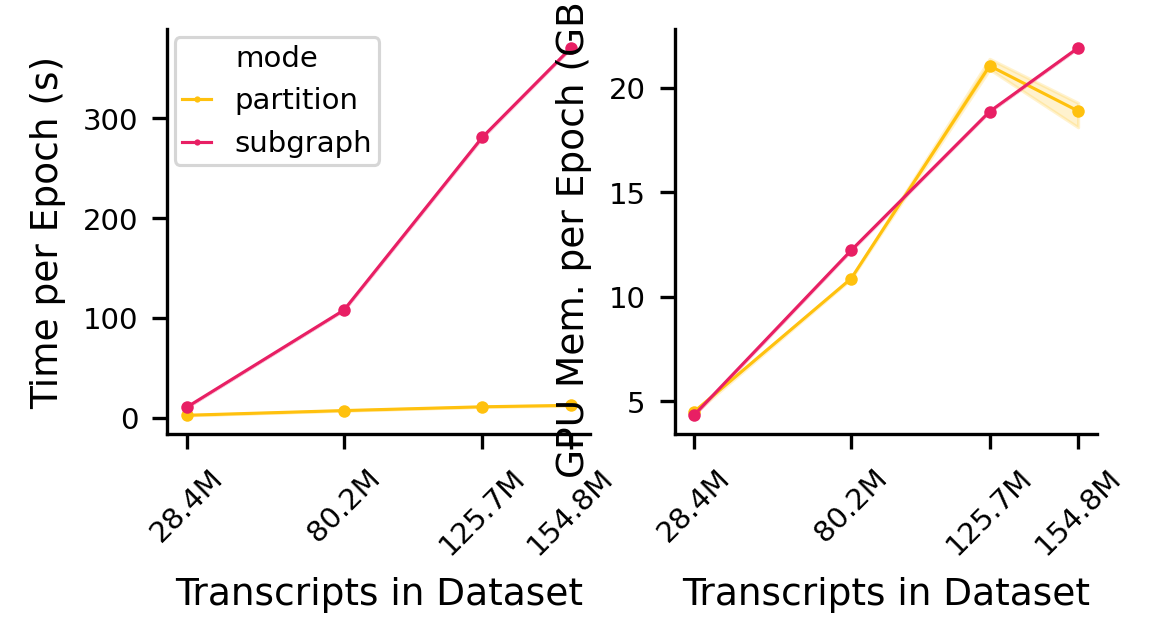

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(4, 1.75))
labels = {"time": "Time per Epoch (s)", "memory": "GPU Mem. per Epoch (GB)"}
data = loaders.with_columns(pl.col("memory") / 1e9)
ticks = sorted(data["transcripts"].unique())
for ax, (column, label) in zip(axes, labels.items()):
    sns.lineplot(
        data, x="transcripts", y=column, hue="mode", palette=loader_palette, marker="o", markersize=3,
        markeredgewidth=0, legend=(column == "time"), ax=ax,
    )
    ax.set_xlabel("Transcripts in Dataset")
    ax.set_ylabel(label)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{n / 1e6:.1f}M" for n in ticks], rotation=45)
sg.pl.save_panel(fig, OUT_DIR / "panel_bc")

## Panels d and e: what the margin costs

Tiles cut the edges that cross their boundaries; nodes within two hops of a cut edge have a truncated receptive field.
Complete nodes, `1 - node_all_khop_interior / node_all_total`; training data, `node_all_interior / node_all_total`.
Panel d sweeps the margin on the lung cancer section; panel e evaluates every dataset at its own three-hop margin.

In [6]:
CAPACITIES = [25_000, 50_000, 100_000, 250_000, 500_000]
MARGINS = [0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0]
MARGIN_SAMPLE = "xenium_nsclc"


def margin_impact(sample, capacities, margins, k=2):
    """Nodes and edges lost to tile boundaries for each capacity and margin (``None``: the dataset's 3-hop margin)."""
    data_module = ISTDataModule(raw_dirs[sample], tiling_margin_training=0.0, tiling_margin_prediction=0.0)
    data_module.data = data_module.data.cuda()
    hop_margin = estimate_hop_margin(data_module.data)
    rows = []
    for capacity in tqdm(capacities, leave=False):
        tiling = QuadTreeTiling(data_module.data["tx"]["pos"], capacity)
        for margin in margins if margins is not None else [hop_margin]:
            rows.append(dict(
                **khop_impact(data_module.data, tiling, margin=margin, k=k),
                sample=sample, capacity=capacity, margin=margin, hop_margin=hop_margin,
            ))
        torch.cuda.empty_cache()
    del data_module
    torch.cuda.empty_cache()
    return pl.DataFrame(rows)


def add_fractions(frame):
    return frame.with_columns(
        (1 - pl.col("node_all_khop_interior") / pl.col("node_all_total")).alias("complete_nodes"),
        (pl.col("node_all_interior") / pl.col("node_all_total")).alias("training_data"),
    )


labels = {"complete_nodes": "Fraction\nComplete Nodes", "training_data": "Fraction\nTraining Data"}

  tx-neighbors-tx edges: 627,276,264


  tx-belongs-bd edges: 46,793,754


  tx-neighbors-bd edges: 134,008,081


  0%|          | 0/5 [00:00<?, ?it/s]

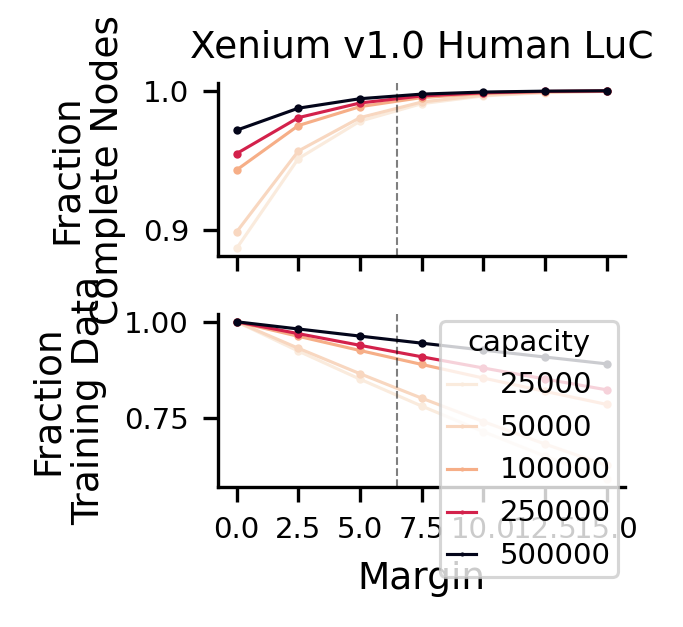

In [7]:
path_margins = OUT_DIR / "margin_sweep.parquet"
if path_margins.exists():
    margin_sweep = pl.read_parquet(path_margins)
else:
    margin_sweep = margin_impact(MARGIN_SAMPLE, CAPACITIES, MARGINS)
    margin_sweep.write_parquet(path_margins)
margin_sweep = add_fractions(margin_sweep)

fig, axes = plt.subplots(2, 1, figsize=(1.75, 1.75), sharex=True, gridspec_kw=dict(hspace=1 / 3))
for ax, (column, label) in zip(axes, labels.items()):
    sns.lineplot(
        margin_sweep, x="margin", y=column, hue="capacity", palette="rocket_r", marker="o", markersize=2,
        markeredgewidth=0, legend=(column == "training_data"), ax=ax,
    )
    ax.axvline(margin_sweep["hop_margin"][0], lw=0.5, ls="--", c="k", alpha=0.5)
    ax.set_ylabel(label)
axes[0].set_xticks(MARGINS)
axes[0].set_title(SAMPLES[MARGIN_SAMPLE].replace("\n", " "))
axes[1].set_xlabel("Margin")
sg.pl.save_panel(fig, OUT_DIR / "panel_d")

  0%|          | 0/4 [00:00<?, ?it/s]

  tx-neighbors-tx edges: 141,982,795


  tx-belongs-bd edges: 11,447,655


  tx-neighbors-bd edges: 23,990,512


Invalid quadtree generated with max_size=50000. Retry with max_size=60000.


  0%|          | 0/5 [00:00<?, ?it/s]

... (10 outputs left out)

  tx-belongs-bd edges: 24,966,015


  tx-neighbors-bd edges: 106,311,428


  0%|          | 0/5 [00:00<?, ?it/s]

Invalid quadtree generated with max_size=100000. Retry with max_size=110000.


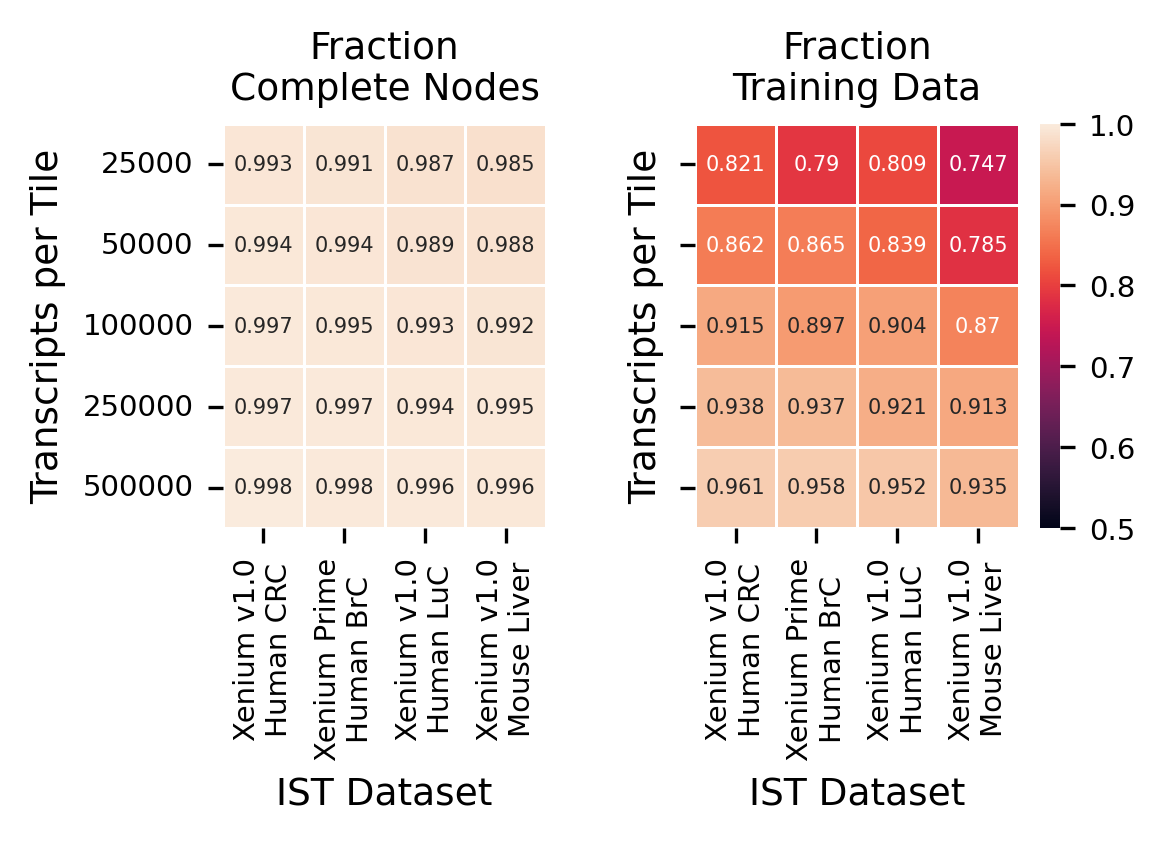

In [8]:
path_capacities = OUT_DIR / "margin_by_dataset.parquet"
if path_capacities.exists():
    by_dataset = pl.read_parquet(path_capacities)
else:
    by_dataset = pl.concat([margin_impact(sample, CAPACITIES, margins=None) for sample in tqdm(SAMPLES)])
    by_dataset.write_parquet(path_capacities)
by_dataset = add_fractions(by_dataset)

fig, axes = plt.subplots(1, 2, figsize=(4, 1.75), sharey=True)
for ax, (column, title) in zip(axes, labels.items()):
    matrix = (
        by_dataset.pivot(on="sample", index="capacity", values=column)
        .to_pandas()
        .set_index("capacity")
        .rename(columns=SAMPLES)
    )
    sns.heatmap(
        matrix, vmin=0.5, vmax=1.0, annot=True, fmt=".3g", annot_kws=dict(fontsize=5), linewidth=0.25, square=True,
        cbar=(column == "training_data"), cmap="rocket", ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("IST Dataset")
    ax.set_ylabel("Transcripts per Tile")
sg.pl.save_panel(fig, OUT_DIR / "panel_e")

## Software versions

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
matplotlib,3.10.8
polars,1.40.0
scanpy,1.11.5
seaborn,0.13.2
torch,2.5.1+cu121
segger,0.1.0
tqdm,4.67.3
numpy,1.26.4
pandas,2.2.2
Component,Info
